In [8]:
#Parámetros

import warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.signal import find_peaks
from scipy.ndimage import uniform_filter1d, median_filter

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 100

carpeta = "datos_HI"
f_lo = 1420.0e6
fs = 5.0e6
n_fft = 1024
lat = -33.457
lon = -70.664
T_hot = 295.0
T_cold = 80.0
R0 = 8.5
V0 = 220.0


f_hi = 1420.405751768e6
c = 299792.458
dv = c / f_hi * fs / n_fft
v_grid = np.arange(-300, 450, dv)

In [9]:
#Funciones Astronómicas

def juliano(t): #Convierte fechas UTC a tiempo juliano
    y, m = t.year, t.month
    d = t.day + (t.hour + (t.minute + t.second / 60) / 60) / 24
    if m <= 2:
        y -= 1
        m += 12
    a = y // 100
    b = 2 - a + a // 4
    return int(365.25 * (y + 4716)) + int(30.6001 * (m + 1)) + d + b - 1524.5

def gmst(jd): #Tiempo GMST
    T = (jd - 2451545.0) / 36525
    return (280.46061837 + 360.98564736629 * (jd - 2451545.0) + 0.000387933 * T**2 - T**3 / 38710000) % 360

def lam_sol(jd): #Longitud solar
    T = (jd - 2451545.0) / 36525
    L0 = 280.46646 + 36000.76983 * T
    M = np.radians(357.52911 + 35999.05029 * T)
    C = (1.914602 - 0.004817 * T) * np.sin(M) + 0.019993 * np.sin(2 * M) + 0.000289 * np.sin(3 * M)
    return (L0 + C) % 360

def rot_z(a): #Rotación alrededor del eje z para precesion
    return np.array([[np.cos(a), -np.sin(a), 0], [np.sin(a), np.cos(a), 0], [0, 0, 1]])

def rot_y(a): #Rotación alrededor del eje y para precesion
    return np.array([[np.cos(a), 0, np.sin(a)], [0, 1, 0], [-np.sin(a), 0, np.cos(a)]])

def vec(ra, dec): #vector unitario de una direccion del cielo
    ra, dec = np.radians(ra), np.radians(dec)
    return np.array([np.cos(dec) * np.cos(ra), np.cos(dec) * np.sin(ra), np.sin(dec)])

A_gal = np.array([[-0.0548755604, -0.8734370902, -0.4838350155], #Convierte coordenadas ecuatoriales a galácticas
                  [0.4941094279, -0.4448296300, 0.7469822445],
                  [-0.8676661490, -0.1980763734, 0.4559837762]])
apice = vec(270.9596, 30.0047) #Direccion del apice solar (RA, Dec J2000)

def correccion(t, az, el): #Junta todo lo anterior
    jd = juliano(t)
    T = (jd - 2451545.0) / 36525
    lst = (gmst(jd) + lon) % 360
    a, A, p = np.radians(el), np.radians(az), np.radians(lat)
    dec = np.arcsin(np.sin(a) * np.sin(p) + np.cos(a) * np.cos(p) * np.cos(A))
    H = np.arctan2(-np.cos(a) * np.sin(A), np.sin(a) * np.cos(p) - np.cos(a) * np.sin(p) * np.cos(A))
    ra = np.radians(lst) - H
    s = np.array([np.cos(dec) * np.cos(ra), np.cos(dec) * np.sin(ra), np.sin(dec)]) #Direccion a donde apunta la antena

    #Calculo de la velocidad de la tierra alrededor del sol y proyeccion sobre s
    L = np.radians(lam_sol(jd) + 180)
    e = 0.016708634 - 0.000042037 * T
    w = np.radians(102.93735 + 1.71946 * T)
    k = 29.7847 / np.sqrt(1 - e**2)
    eps = np.radians(23.4392911 - 0.0130042 * T)
    vx = k * (-np.sin(L) - e * np.sin(w))
    vy = k * (np.cos(L) + e * np.cos(w))
    v_tierra = np.array([vx, vy * np.cos(eps), vy * np.sin(eps)])
    v_orb = v_tierra @ s

    #Calculo de la velocidad de rotacion de la tierra y proyeccion sobre s
    omega, Re = 7.292115e-5, 6378.137
    v_obs = omega * Re * np.cos(p) * np.array([-np.sin(np.radians(lst)), np.cos(np.radians(lst)), 0])
    v_rot = v_obs @ s

    #Pasa las coordenadas de s a J2000 y luego a coordenadas galácticas para calcular la velocidad del sol proyectada sobre s
    z = np.radians((2306.2181 * T + 1.09468 * T**2 + 0.018203 * T**3) / 3600)
    zeta = np.radians((2306.2181 * T + 0.30188 * T**2 + 0.017998 * T**3) / 3600)
    th = np.radians((2004.3109 * T - 0.42665 * T**2 - 0.041833 * T**3) / 3600)
    P = rot_z(z) @ rot_y(-th) @ rot_z(zeta)
    s_j = P.T @ s
    ra_j = np.degrees(np.arctan2(s_j[1], s_j[0])) % 360
    g = A_gal @ s_j
    l = np.degrees(np.arctan2(g[1], g[0])) % 360
    b = np.degrees(np.arcsin(g[2]))
    v_sol = 20.0 * (apice @ s_j)
    return l, b, ra_j, v_rot + v_orb + v_sol

In [10]:
#Lectura
obs = pd.read_csv(carpeta + "/observaciones.csv")
obs["t_utc"] = pd.to_datetime(obs["t_utc"], utc=True)

f = f_lo + np.fft.fftshift(np.fft.fftfreq(n_fft, 1 / fs))
v_topo = c * (f_hi - f) / f_hi
usable = np.abs(f - f_lo) < 0.94 * fs / 2

P = np.zeros((len(obs), n_fft))
t_mid = []
for i in range(len(obs)):
    datos = np.fromfile(carpeta + "/" + obs.file[i], dtype="<u4").reshape(-1, n_fft).astype(float)
    datos = np.fft.fftshift(datos, axes=1)
    t_frame = obs.n_int[i] * n_fft / fs
    t_mid.append(obs.t_utc[i] + pd.Timedelta(seconds=len(datos) * t_frame / 2))
    banda = np.median(datos[:, n_fft // 8:-n_fft // 8], axis=1)
    datos = datos[np.abs(banda / np.median(banda) - 1) < 0.01]
    p = datos.mean(axis=0)
    mal = p / median_filter(p, 5) - 1 > 0.015
    mal = np.convolve(mal, np.ones(3), "same") > 0
    p[mal] = np.interp(np.where(mal)[0], np.where(~mal)[0], p[~mal])
    P[i] = p


In [11]:
hot = obs.index[obs.kind == "hot"]
cold = obs.index[obs.kind == "cold"]
cal_t, cal_G, cal_Trx = [], [], []
for h, k in zip(hot, cold):
    Y = P[h] / P[k]
    G = (P[h] - P[k]) / (T_hot - T_cold)
    Trx = (T_hot - Y * T_cold) / (Y - 1)
    cal_t.append(t_mid[h].timestamp())
    cal_G.append(uniform_filter1d(G, 41, mode="nearest"))
    cal_Trx.append(uniform_filter1d(Trx, 41, mode="nearest"))
cal_t = np.array(cal_t)

cielo = obs.index[obs.kind == "sky"]
T_ant = np.full((len(obs), n_fft), np.nan)
for i in cielo:
    j = np.argmin(np.abs(cal_t - t_mid[i].timestamp()))
    T_ant[i] = P[i] / cal_G[j] - cal_Trx[j]

In [12]:
lb = pd.DataFrame(np.nan, index=obs.index, columns=["l", "b", "ra", "vcorr"])
T_lsr = np.full((len(obs), len(v_grid)), np.nan)
for i in cielo:
    lb.loc[i] = correccion(t_mid[i], obs.az_deg[i], obs.el_deg[i])
    v = v_topo[usable] + lb.vcorr[i]
    orden = np.argsort(v)
    T_lsr[i] = np.interp(v_grid, v[orden], T_ant[i][usable][orden], left=np.nan, right=np.nan)

In [13]:
TB = np.full_like(T_lsr, np.nan)
rms = np.full(len(obs), np.nan)
cont = np.full(len(obs), np.nan)
for i in cielo:
    b = lb.b[i]
    ventana = 80 if abs(b) > 30 else (150 if abs(b) > 10 else 260)
    m = np.isfinite(T_lsr[i]) & (np.abs(v_grid) > ventana)
    coef = np.polyfit(v_grid[m] / 300, T_lsr[i][m], 3)
    base = np.polyval(coef, v_grid / 300)
    TB[i] = T_lsr[i] - base
    rms[i] = np.std(TB[i][m])
    cont[i] = base.mean()

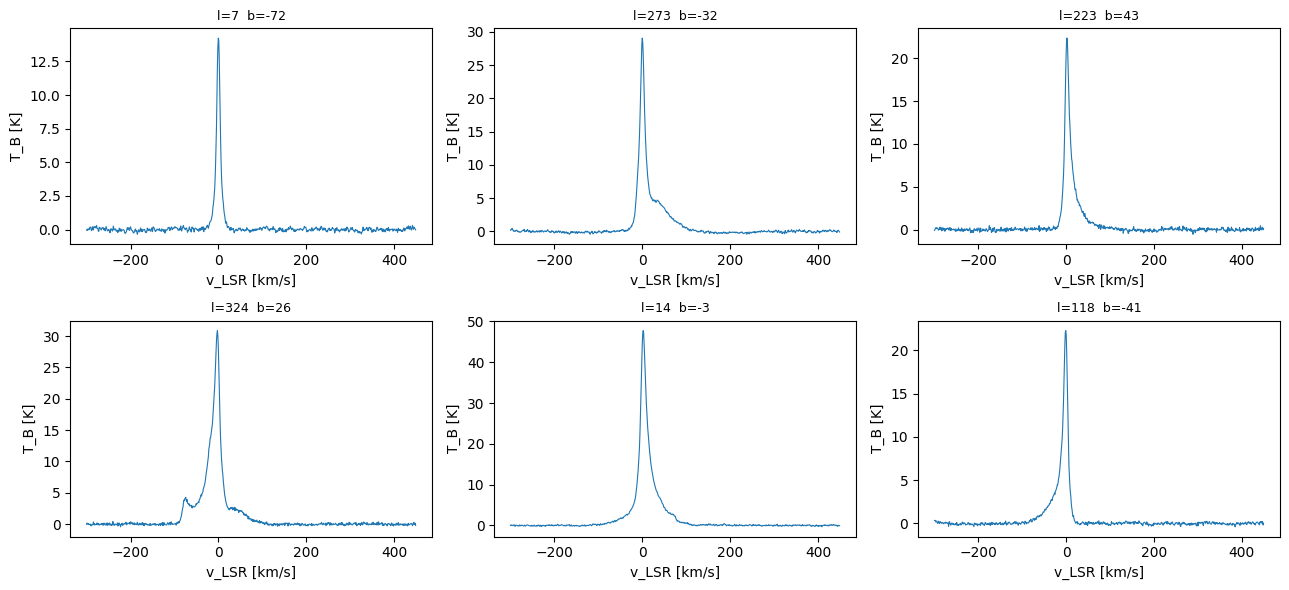

In [14]:
plt.figure(figsize=(13, 6))
sel = cielo[np.linspace(0, len(cielo) - 1, 6).astype(int)]
for n, i in enumerate(sel):
    plt.subplot(2, 3, n + 1)
    plt.plot(v_grid, TB[i], lw=0.8)
    plt.title("l=%.0f  b=%.0f" % (lb.l[i], lb.b[i]), fontsize=9)
    plt.xlabel("v_LSR [km/s]")
    plt.ylabel("T_B [K]")
plt.tight_layout()
plt.show()

perfiles = pd.DataFrame(TB[cielo].T, columns=obs.file[cielo].values)
perfiles.insert(0, "v_lsr", v_grid)
perfiles.to_csv("perfiles_velocidad.csv", index=False)

info = pd.DataFrame({"file": obs.file[cielo].values, "t_utc": [t_mid[i] for i in cielo],
                     "az_deg": obs.az_deg[cielo].values, "el_deg": obs.el_deg[cielo].values,
                     "l": lb.l[cielo].values, "b": lb.b[cielo].values,
                     "v_corr": lb.vcorr[cielo].values, "rms_K": rms[cielo]})
info.to_csv("info_observaciones.csv", index=False)

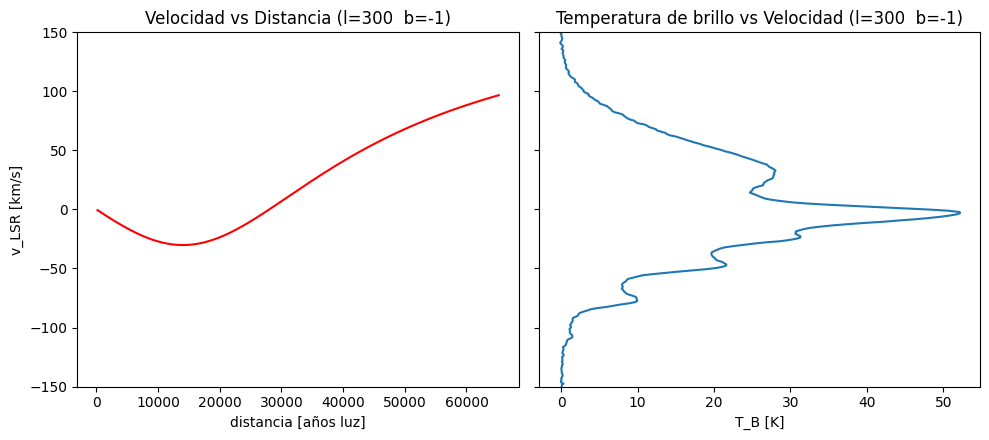

In [19]:
#Perfil velocidad vs distancia

l_obj = 300
plano = cielo[np.abs(lb.b[cielo]) < 5]
i = plano[np.argmin(np.abs(((lb.l[plano] - l_obj + 180) % 360) - 180))]
l, b = np.radians(lb.l[i]), np.radians(lb.b[i])

d = np.linspace(0.05, 20, 400)
R = np.sqrt(R0**2 + (d * np.cos(b))**2 - 2 * R0 * d * np.cos(b) * np.cos(l))
v = V0 * (R0 / R - 1) * np.sin(l) * np.cos(b)

fig, ax = plt.subplots(1, 2, figsize=(10, 4.5), sharey=True)
ax[0].plot(d * 3261.56, v, color = "red")
ax[0].set_xlabel("distancia [años luz]")
ax[0].set_ylabel("v_LSR [km/s]")
ax[0].set_title("Velocidad vs Distancia (l=%.0f  b=%.0f)" % (lb.l[i], lb.b[i]))
ax[1].plot(TB[i], v_grid)
ax[1].set_xlabel("T_B [K]")
ax[0].set_ylim(-150, 150)
ax[1].set_title("Temperatura de brillo vs Velocidad (l=%.0f  b=%.0f)" % (lb.l[i], lb.b[i]))
plt.tight_layout()
plt.show()